# Redes y análisis topológico de comunidades microbianas de la rizosfera

del tomate (versión 2)

# 0. Instaslar y preparar datos

Descomenta estas líneas y ejecuta para instalar los paquetes en caso de
que no los tengas instalados.

In [3]:
#instalar paquetes
#!pip install gudhi
#%pip install biom-format
#import biom
#print("BIOM instalado correctamente")

Primero Cargaremos los paquetes necesarios para nuestro proyecto.

In [1]:
import biom #Paquete para trabajar con archivos biom
import pandas as pd #Paquete para trabajar con dataframes
import numpy as np #Paquete para trabajar con arreglos y matrices
import networkx as nx #Paquete para trabajar con grafos
import matplotlib.pyplot as plt #Paquete para graficar
import matplotlib.colors as mcolors #Paquete para trabajar con colores
from scipy import stats #Paquete para trabajar con estadística
from itertools import combinations #Paquete para trabajar con combinaciones
import gudhi as  gd #Paquete para trabajar con topología algebraica
import os #Paquete para trabajar con el sistema operativo
import seaborn as sns #Paquete para trabajar con visualización de datos
from sklearn.metrics.pairwise import pairwise_distances #Paquete para calcular distancias entre pares de muestras
import re #Paquete para trabajar con expresiones regulares

Vamos a cargar los datos sobre presencia de diferentes microorganismos
en plantas, que cuentan con información sobre la especie de planta, el
tipo de microorganismo y la cantidad presente, etc. Esto nos permitirá
analizar la diversidad microbiana en diferentes especies de plantas y
cómo varía según el tipo de microorganismo.

In [ ]:
# Definir de donde salen los datos

workdir = "subset"

# Mostrar los archivos disponibles
print(os.listdir(workdir))

['taller_genus.biom', 'taller_metadata.csv', 'taller_samples.csv', 'subset_log.txt']

# 1. Lectura y exploración de datos

In [ ]:
# Establecer la ruta del archivo BIOM (asegúrate de cambiarlo a tu ruta local)
BIOM_PATH= archivo = os.path.join(workdir, "taller_genus.biom")

# Cargar la tabla BIOM
table = biom.load_table(BIOM_PATH)

# función que extrae la información de taxonomía de la tabla BIOM y la convierte en un DataFrame de pandas
# Función que extrae y limpia la información taxonómica de una tabla BIOM
def extract_taxonomies(biom_table):
    """
    Extrae la taxonomía de una tabla BIOM y la convierte
    en un DataFrame de pandas, eliminando los prefijos
    taxonómicos (k__, p__, c__, o__, f__, g__).
    """

    ranks = ['domain', 'phylum', 'class', 'order', 'family', 'genus']
    feature_ids = biom_table.ids(axis='observation')
    taxonomy_rows = []

    for feature_id in feature_ids:
        metadata = biom_table.metadata(feature_id, axis='observation') or {}
        taxonomy = list(metadata.get('taxonomy') or [])

        # Eliminar los prefijos taxonómicos
        taxonomy = [
            name.split('__', 1)[1] if isinstance(name, str) and '__' in name
            else name
            for name in taxonomy
        ]

        # Completar con None si faltan niveles taxonómicos
        taxonomy_rows.append(
            (taxonomy + [None] * len(ranks))[:len(ranks)]
        )

    return pd.DataFrame(
        taxonomy_rows,
        index=feature_ids,
        columns=ranks
    )
# Convertir la tabla BIOM a un DataFrame de pandas y extraer la información de taxonomía (con la función definida anteriormente)
counts_df = table.to_dataframe(dense=True)
taxonomy_df = extract_taxonomies(table)

La tabla de conteo (counts_df) contiene la información de abundancia de
cada microorganismo en cada muestra, podemos observar que el índice
corresponde al nombre de la muestra del microorganismo y las columnas
corresponden a los diferentes muestras tomadas con la abundancia de cada
microorganismo en cada muestra.

In [ ]:
print(" La forma de la tabla de conteo es:", counts_df.shape)
counts_df.head()

 La forma de la tabla de conteo es: (3330, 75)

5 rows × 75 columns

La tabla de taxonomía (taxonomy_df) contiene información sobre la
clasificación taxonómica de cada microorganismo, incluyendo el dominio,
filo, clase, orden, familia, género y especie. Esto nos permitirá
analizar la diversidad microbiana a diferentes niveles taxonómicos y
cómo varía según la especie de planta y el tipo de microorganismo.

In [ ]:
print(" La forma de la tabla de taxonomía es:", taxonomy_df.shape)
taxonomy_df.head()

 La forma de la tabla de taxonomía es: (3330, 6)

Para tener la información completa, cargamos la tabla de metadatos
(metadata_df) que contiene información sobre las muestras, incluyendo el
nombre de la muestra, la especie de planta, el tipo de microorganismo y
otros detalles relevantes. Esto nos permitirá relacionar la información
de abundancia y taxonomía con las características de las muestras y
realizar análisis más completos sobre la diversidad microbiana en
diferentes especies de plantas.

In [ ]:
# Recuerda adaptar la ruta del archivo CSV a tu entorno local
metadata_df = pd.read_csv(
    os.path.join(workdir, "taller_metadata.csv"),
    index_col="sample_id"
)
metadata_df.head()

5 rows × 21 columns

## 1.1. ¿De qué plantas proceden las muestras?

Comenzaremos explorando la distribución de las muestras de rizosfera
según la especie de planta de la que provienen. Esto nos permitirá
identificar cuáles son las especies de plantas mejor representadas en
nuestro conjunto de datos.

Observamos que el tomate (Tomato) es la especie con mayor número de
muestras. Por ello, centraremos nuestro análisis en las comunidades
microbianas de la rizosfera del tomate, evitando introducir diferencias
asociadas a distintas especies de plantas.

En las siguientes secciones, exploraremos si la composición de estas
comunidades microbianas varía según el país de procedencia de las
muestras, utilizando la distancia de Bray-Curtis para cuantificar las
diferencias entre ellas.

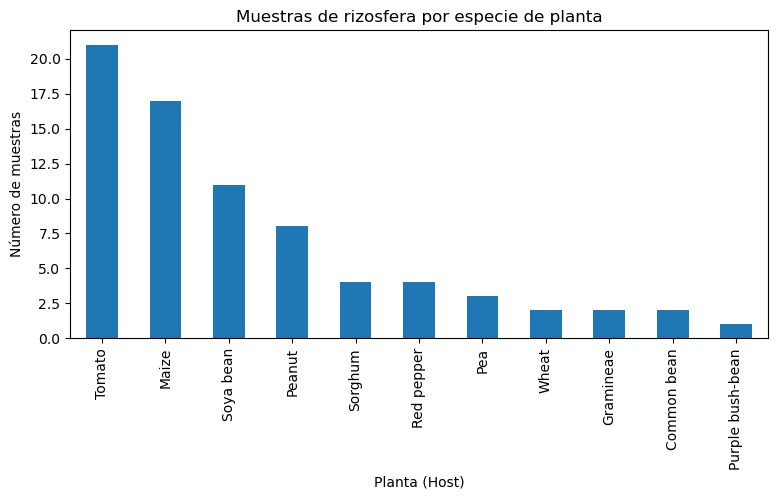

In [ ]:
host_count = metadata_df['host_name'].value_counts()
plt.subplots(figsize=(9, 4))
host_count.plot(kind='bar', title='Muestras de rizosfera por especie de planta', xlabel='Planta (Host)', ylabel='Número de muestras')

## 1.2 selección de tomate y evaluación del tamaño de muestra

**Antes de comparar países**, revisamos su representación. Con pocos
replicados por país, las correlaciones entre géneros son especialmente
inestables. Las muestras sin país conocido se excluyen del análisis
geográfico.

In [ ]:
host_value = "Tomato"
tomato_meta = metadata_df.loc[
    metadata_df["host_name"].eq(host_value) & metadata_df["country"].notna()
].copy().sort_values("country")
tomato_counts = counts_df.loc[:, tomato_meta.index]
nonempty = tomato_counts.sum(axis=0) > 0
tomato_counts = tomato_counts.loc[:, nonempty]
tomato_meta = tomato_meta.loc[tomato_counts.columns]
if tomato_counts.shape[1] < 2:
    raise ValueError("Se necesitan al menos dos muestras de tomate con conteos y país")
country_sizes = tomato_meta["country"].value_counts().sort_index()
print("Muestras de tomate por país:")
display(country_sizes.to_frame("n_muestras"))
if (country_sizes < 5).any():
    print("Advertencia: algunos países tienen menos de 5 muestras; interpretar con cautela.")

Muestras de tomate por país:

# 2. Exploración de abundancias taxonómicas

Para comparar perfiles de composición, normalizamos **cada muestra por
separado**:

$$\text{abundancia relativa} = \frac{\text{conteo del taxón}}{\text{suma de conteos de esa muestra}}.$$

Agrupamos características con la misma etiqueta de género; las etiquetas
ausentes se conservan como `Sin asignar`. En estas gráficas,
`Otros géneros` representa la abundancia que no está entre los 10
principales.

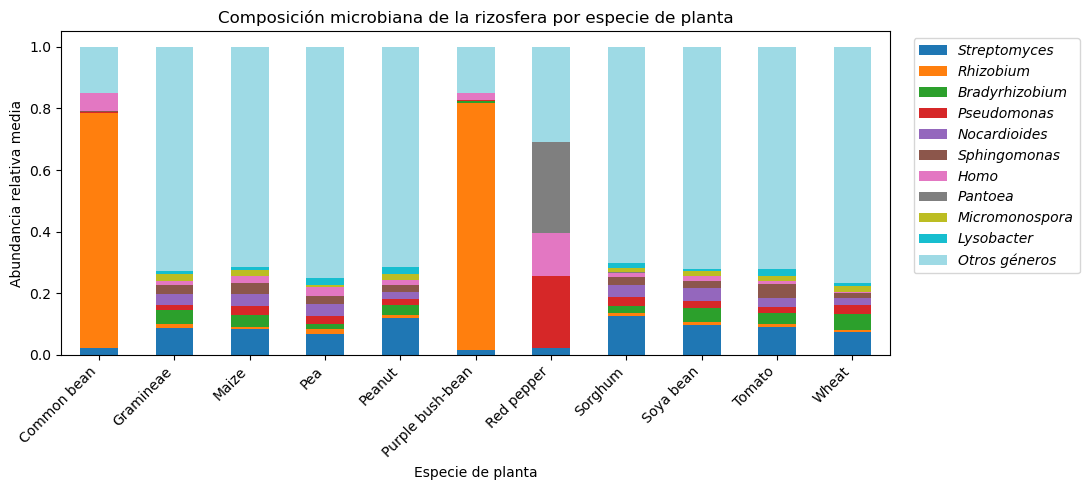

In [ ]:
# 1. Primero limpiamos las etiquetas de género

def clean_genus(x):
    if pd.isna(x) or str(x).strip().lower() in ("", "none", "nan"):
        return "Sin asignar"
    return str(x).strip()


# 2. Obtener las etiquetas taxonómicas correspondientes a cada fila de la matriz de conteos
genus_labels = taxonomy_df["genus"].reindex(counts_df.index).map(clean_genus)

# 3. Agrupamos los conteos por género: sumar los conteos de los taxones que pertenecen al mismo género
genus_counts = counts_df.groupby(genus_labels, sort=False).sum()

# 4. Calculamos abundancias relativas por muestra
genus_rel = genus_counts.div(genus_counts.sum(axis=0).replace(0, np.nan), axis=1)

# 5. Identificamos los 10 géneros más abundantes: calcular abundancia relativa promedio entre muestras y excluir observaciones sin género asignado
top10_global = genus_rel.drop(index="Sin asignar", errors="ignore").mean(axis=1).nlargest(10).index.tolist()

# 6. Calculamos abundancias promedio por especie de planta
rel_by_host = genus_rel.T.join(metadata_df[["host_name"]]).groupby("host_name").mean().T

# 7. Preparamos los datos para la gráfica
host_plot = rel_by_host.reindex(top10_global).T.copy()
host_plot["Otros géneros"] = (1 - host_plot.sum(axis=1)).clip(lower=0)

# 8. Realizamos el plot
ax = host_plot.plot.bar(stacked=True, figsize=(11, 5), colormap="tab20")

ax.set(xlabel="Especie de planta",
       ylabel="Abundancia relativa media",
       title="Composición microbiana de la rizosfera por especie de planta"
)

# Los géneros van en cursiva, manipulamos la leyenda para eso
# Obtener los elementos de la leyenda
handles, labels = ax.get_legend_handles_labels()

# Crear la leyenda
legend = ax.legend(handles, labels, bbox_to_anchor=(1.02, 1), loc="upper left")

# Poner en cursivas los nombres de los géneros
for text in legend.get_texts():
    if text.get_text() != "Otros taxones y sin asignar":
        text.set_fontstyle("italic")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## 2.1. Perfiles de las muestras de tomate por país

La gráfica siguiente muestra **cada muestra individual**. Los 10 géneros
se eligen globalmente entre las muestras de tomate para mantener
categorías comparables.

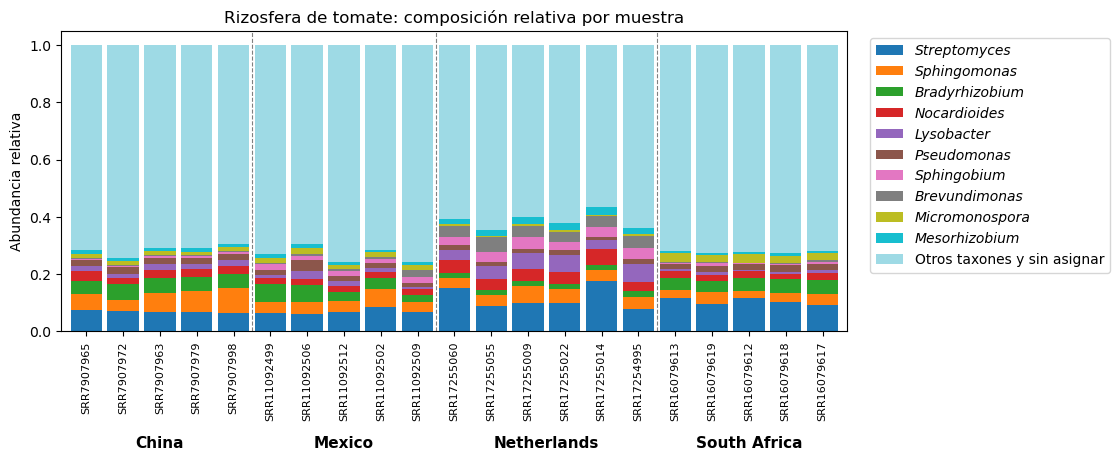

In [ ]:
# 1. Seleccionar las muestras de tomate
tomato_genus_rel = genus_rel.loc[:, tomato_meta.index]

# 2. Seleccionar los 10 géneros más abundantes (excluyendo los no asignados)
top10_tomato = tomato_genus_rel.drop(index="Sin asignar", errors="ignore").mean(axis=1).nlargest(10).index.tolist()

# 3. Preparar los datos para la gráfica
plot_samples = tomato_genus_rel.reindex(top10_tomato).T.copy()

plot_samples["Otros taxones y sin asignar"] = (1 - plot_samples.sum(axis=1)).clip(lower=0)

# 4. Agregar el país y ordenar las muestras
plot_samples["country"] = tomato_meta.loc[plot_samples.index, "country"]

plot_samples = plot_samples.sort_values("country")

# Guardar los países antes de graficar
countries = plot_samples.pop("country")

# 5. Crear la gráfica
fig, ax = plt.subplots(figsize=(max(12, 0.5 * len(plot_samples)), 6))

plot_samples.plot.bar(stacked=True, ax=ax, colormap="tab20", width=0.85)

ax.set(title="Rizosfera de tomate: composición relativa por muestra",
       xlabel="",
       ylabel="Abundancia relativa"
)

# 6. Mostrar los identificadores de las muestras
ax.set_xticklabels(plot_samples.index, rotation=90, fontsize=8)

# 7. Agregar separadores y nombres de países
for country in countries.unique():

    positions = np.where(countries.values == country)[0]

    start = positions[0]
    end = positions[-1]
    center = (start + end) / 2

    # Nombre del país debajo de las muestras
    ax.text(center, -0.35, str(country), ha="center", va="top", fontsize=11, fontweight="bold", transform=ax.get_xaxis_transform())

    # Separador entre países
    if end < len(plot_samples) - 1:
        ax.axvline(end + 0.5, color="gray", linestyle="--", linewidth=0.8)

# 8. Leyenda con géneros en cursivas
handles, labels = ax.get_legend_handles_labels()

legend = ax.legend(handles, labels, bbox_to_anchor=(1.02, 1), loc="upper left")

for text in legend.get_texts():
    if text.get_text() != "Otros taxones y sin asignar":
        text.set_fontstyle("italic")

# 9. Ajustar los márgenes
plt.subplots_adjust(bottom=0.38, right=0.78)

plt.show()

# Red de similitud entre muestras mediante Bray-Curtis

La matriz de Bray-Curtis es una medida de disimilitud que se utiliza
para comparar la composición de comunidades microbianas entre diferentes
muestras. Esta matriz nos permitirá analizar la diversidad microbiana en
diferentes especies de plantas y cómo varía según el tipo de
microorganismo y la especie de planta.

La disimilitud Bray–Curtis para vectores de abundancia no negativos es

$$d_{BC}(x,y)=\frac{\sum_k |x_k-y_k|}{\sum_k(x_k+y_k)}.$$

Con abundancias relativas, 0 indica perfiles idénticos y 1 indica que no
comparten abundancia en los mismos géneros. Bray–Curtis no
necesariamente cumple la desigualdad triangular: aquí la empleamos como
**matriz de disimilitudes**.

Calcularemos la matriz de Bray-Curtis para los datos de abundancia de
los microorganismos presentes en las muestras de Tomate, y mostrando las
agrupaciones de las muestras según el continente de origen. Esto nos
permitirá observar cómo varía la diversidad microbiana según el
continente y cómo se relaciona con la especie de planta y el tipo de
microorganismo presente en cada muestra.

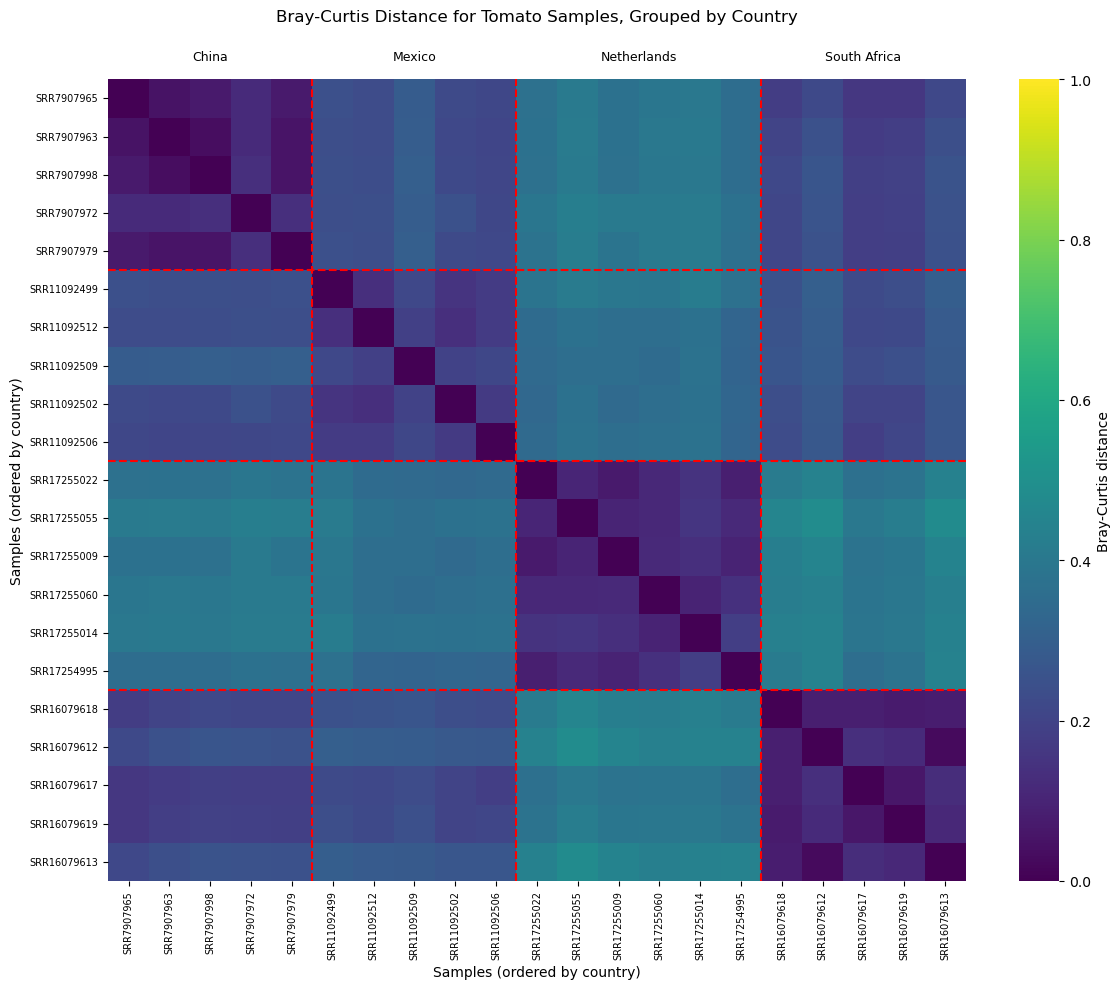

Samples included: 21
country
China           5
Mexico          5
Netherlands     6
South Africa    5
dtype: int64
Matrix shape: (21, 21)
Saved to: subset/Distancia_Bray-curtis/Heatmap/tomato_samples_by_country_braycurtis.jpg

In [ ]:
host_value = 'Tomato'

# Normalizar por muestra antes de calcular Bray-Curtis
relative_counts_df = counts_df.div(
    counts_df.sum(axis=0).replace(0, np.nan), axis=1
)

# Alineamos la metadata de las muestras de BIOM, luego mantenemos las muestras de tomate con un país conocido
tomato_meta = metadata_df.reindex(relative_counts_df.columns)
tomato_meta = tomato_meta.loc[
    tomato_meta['host_name'].eq(host_value) & tomato_meta['country'].notna()
].sort_values(['country'], kind='stable')

tomato_samples = tomato_meta.index.tolist()
if len(tomato_samples) < 2:
    raise ValueError(f'Need at least two {host_value} samples with country metadata.')

# Calculamos la matriz de distancia de Bray-Curtis para las muestras de tomate y creamos un DataFrame para facilitar la visualización
braycurtis_tomato = pairwise_distances(
    relative_counts_df.loc[:, tomato_samples].T,
    metric='braycurtis'
)
braycurtis_tomato_by_country = pd.DataFrame(
    braycurtis_tomato,
    index=tomato_samples,
    columns=tomato_samples
)

# Creamos un heatmap de la matriz de distancia de Bray-Curtis para las muestras de tomate, agrupadas por país
fig, ax = plt.subplots(
    figsize=(max(12, 0.22 * len(tomato_samples) + 5), max(10, 0.18 * len(tomato_samples) + 5))
)
sns.heatmap(
    braycurtis_tomato_by_country,
    cmap='viridis',
    vmin=0,
    vmax=1,
    xticklabels=tomato_samples,
    yticklabels=tomato_samples,
    cbar_kws={'label': 'Bray-Curtis distance'},
    ax=ax
)

# Agregamos líneas de separación y etiquetas de país en el heatmap
country_groups = tomato_meta.groupby('country', sort=False).size()
boundary = 0
for country, sample_count in country_groups.items():
    if boundary > 0:
        ax.axvline(boundary, color='red', linestyle='--', linewidth=1.5)
        ax.axhline(boundary, color='red', linestyle='--', linewidth=1.5)
    ax.text(
        boundary + sample_count / 2,
        1.02,
        country,
        ha='center',
        va='bottom',
        fontsize=9,
        transform=ax.get_xaxis_transform()
    )
    boundary += sample_count

ax.set_title(f'Bray-Curtis Distance for {host_value} Samples, Grouped by Country', pad=42)
ax.set_xlabel('Samples (ordered by country)')
ax.set_ylabel('Samples (ordered by country)')
ax.tick_params(axis='x', labelrotation=90, labelsize=7)
ax.tick_params(axis='y', labelsize=7)
fig.tight_layout()

heatmap_dir = os.path.join(workdir, 'Distancia_Bray-curtis', 'Heatmap')
os.makedirs(heatmap_dir, exist_ok=True)
save_path = os.path.join(heatmap_dir, 'tomato_samples_by_country_braycurtis.jpg')
fig.savefig(save_path, bbox_inches='tight', dpi=150)
plt.show()
plt.close(fig)

print(f'Samples included: {len(tomato_samples)}')
print(country_groups)
print(f'Matrix shape: {braycurtis_tomato_by_country.shape}')
print(f'Saved to: {save_path}')

# 3. Red de similitud

Una vez que tenemos la matriz de Bray-Curtis, podemos construir un grafo
de similitud de microorganismos en las muestras de Tomate, donde los
nodos representan los diferentes microorganismos y las aristas
representan la coocurrencia entre ellos. Esto nos permitirá observar
cómo se relacionan los diferentes microorganismos presentes en las
muestras de Tomate y cómo varía la diversidad microbiana según el
continente y la especie de planta.

Cada nodo es una **muestra**. Se añade una arista si su disimilitud es
menor o igual a $\varepsilon$. El umbral de 0.2 se utiliza **como
ejemplo visual**, no como resultado óptimo ni como evidencia de
agrupación. La posición de los nodos se calcula a partir de la red,
**sin imponer centros geográficos**. Los colores solo se añaden al
final.

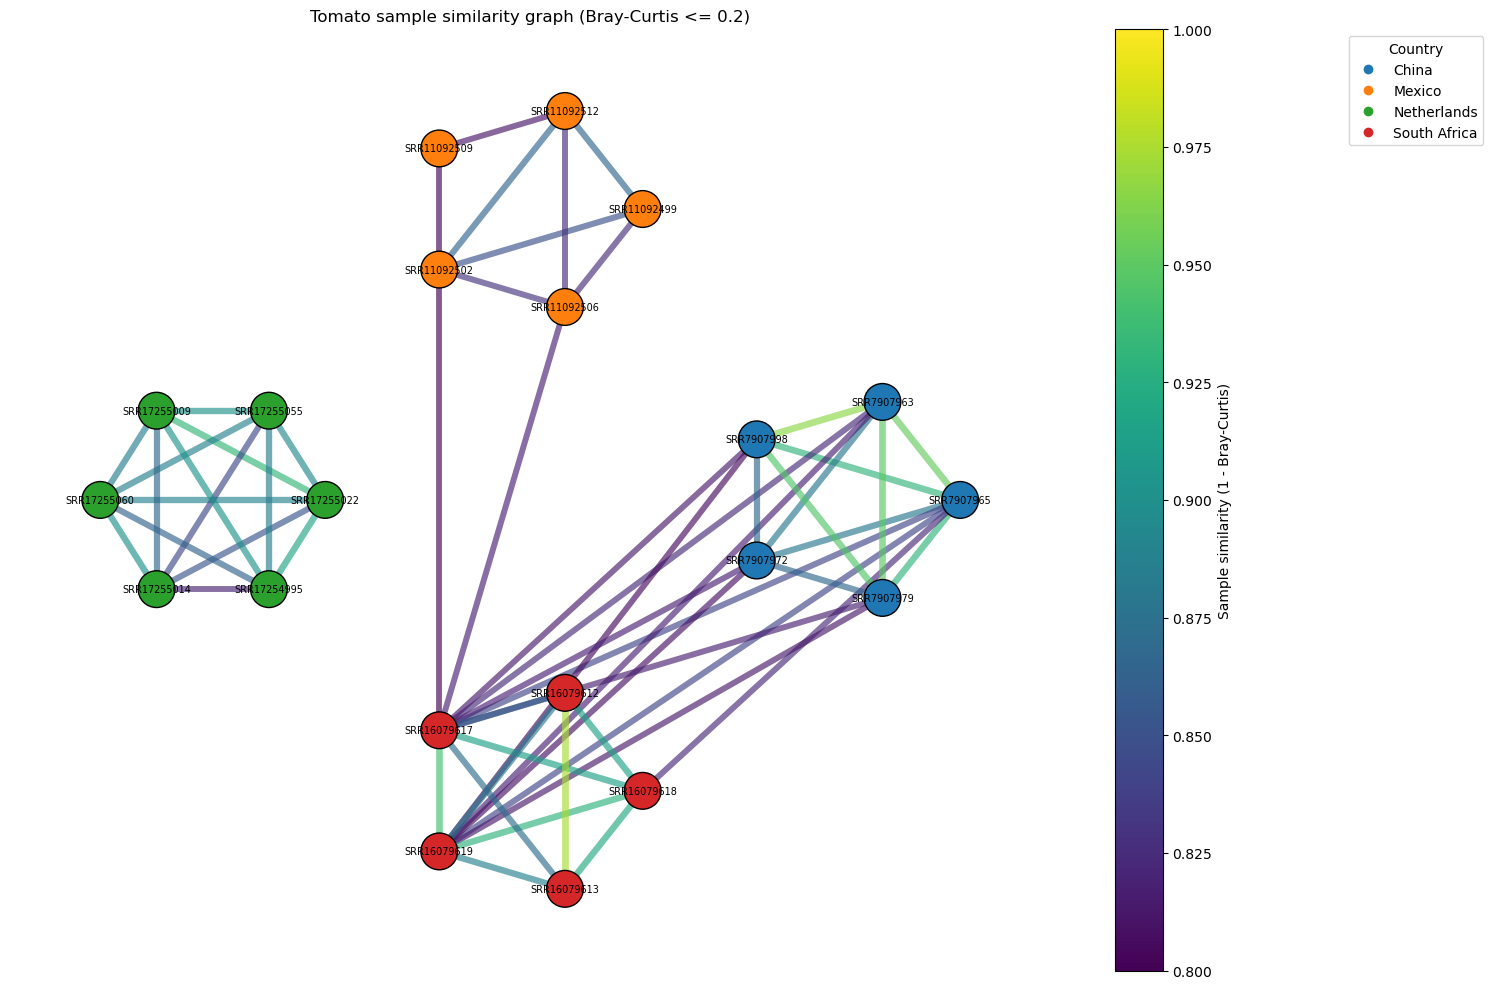

Nodes: 21
Edges: 56
Countries: 4
Saved to: subset/Grafos/Tomato/tomato_braycurtis_similarity_graph.png

In [ ]:
max_braycurtis_distance = 0.2

sample_meta = metadata_df.reindex(braycurtis_tomato_by_country.index)
sample_meta = sample_meta.loc[sample_meta['country'].notna()]
sample_ids = sample_meta.index.intersection(braycurtis_tomato_by_country.index, sort=False)
distance_df = braycurtis_tomato_by_country.loc[sample_ids, sample_ids]
sample_meta = sample_meta.loc[sample_ids]

country_names = sorted(sample_meta['country'].unique())
country_palette = {
    country: plt.cm.tab10(i % 10)
    for i, country in enumerate(country_names)
}

tomato_sample_graph = nx.Graph(host_name='Tomato')
for sample_id, row in sample_meta.iterrows():
    tomato_sample_graph.add_node(sample_id, country=row['country'])

for sample_a, sample_b in combinations(sample_ids, 2):
    distance = distance_df.loc[sample_a, sample_b]
    if distance <= max_braycurtis_distance:
        tomato_sample_graph.add_edge(
            sample_a,
            sample_b,
            braycurtis_distance=distance,
            similarity=1 - distance
        )

country_centers = {
    country: (
        2.4 * np.cos(2 * np.pi * i / len(country_names)),
        2.4 * np.sin(2 * np.pi * i / len(country_names))
    )
    for i, country in enumerate(country_names)
}
pos = {}
for country in country_names:
    country_samples = [
        sample_id for sample_id in tomato_sample_graph.nodes
        if tomato_sample_graph.nodes[sample_id]['country'] == country
    ]
    local_pos = nx.circular_layout(country_samples, scale=0.85)
    center_x, center_y = country_centers[country]
    for sample_id, (x, y) in local_pos.items():
        pos[sample_id] = (center_x + x, center_y + y)

fig, ax = plt.subplots(figsize=(15, 10))
edge_similarities = [
    tomato_sample_graph[u][v]['similarity']
    for u, v in tomato_sample_graph.edges
]
if edge_similarities:
    nx.draw_networkx_edges(
        tomato_sample_graph,
        pos,
        ax=ax,
        width=[1 + 4 * value for value in edge_similarities],
        edge_color=edge_similarities,
        edge_cmap=plt.cm.viridis,
        edge_vmin=1 - max_braycurtis_distance,
        edge_vmax=1,
        alpha=0.65
    )
nx.draw_networkx_nodes(
    tomato_sample_graph,
    pos,
    ax=ax,
    node_size=700,
    node_color=[
        country_palette[tomato_sample_graph.nodes[node]['country']]
        for node in tomato_sample_graph.nodes
    ],
    edgecolors='black'
)
nx.draw_networkx_labels(
    tomato_sample_graph,
    pos,
    ax=ax,
    labels={node: node for node in tomato_sample_graph.nodes},
    font_size=7
)
ax.legend(
    handles=[
        plt.Line2D([], [], marker='o', linestyle='', color=country_palette[country], label=country)
        for country in country_names
    ],
    title='Country', loc='upper left', bbox_to_anchor=(1.28, 1.0)
)
if edge_similarities:
    edge_mapper = plt.cm.ScalarMappable(
        norm=plt.Normalize(vmin=1 - max_braycurtis_distance, vmax=1),
        cmap=plt.cm.viridis
    )
    fig.colorbar(edge_mapper, ax=ax, label='Sample similarity (1 - Bray-Curtis)')
ax.set_title(
    f'Tomato sample similarity graph (Bray-Curtis <= {max_braycurtis_distance})'
)
ax.axis('off')
fig.tight_layout()

graph_dir = os.path.join(workdir, 'Grafos', 'Tomato')
os.makedirs(graph_dir, exist_ok=True)
save_path = os.path.join(graph_dir, 'tomato_braycurtis_similarity_graph.png')
fig.savefig(save_path, bbox_inches='tight', dpi=150)
plt.show()
plt.close(fig)

print(f'Nodes: {tomato_sample_graph.number_of_nodes()}')
print(f'Edges: {tomato_sample_graph.number_of_edges()}')
print(f'Countries: {len(country_names)}')
print(f'Saved to: {save_path}')

# 4. Homología persistente con complejo de Vietoris Rips

Aquí deberíamos introducir cosas teóricas de TDA, algo muy muy breve,
tipo esto:
https://carpentries-incubator.github.io/topological-data-analysis/01-introduction/index.html

En vez de fijar un solo $\varepsilon$, dejamos que el umbral aumente.
Cada arista aparece cuando la disimilitud de sus extremos alcanza el
umbral; los triángulos y símplices superiores aparecen cuando todas sus
aristas están presentes. Así estudiamos **$H_0$** (componentes que se
fusionan) y **$H_1$** (ciclos no rellenados que aparecen y desaparecen).
Un ciclo en el grafo puede estar rellenado por triángulos en el
complejo, por lo que no necesariamente genera una clase de $H_1$.

Ahora calculemos el diagrama de persistencia asociado a la matriz de
Bray-Curtis, que nos permitirá observar la topología de la red de
coocurrencia en las muestras de Tomate y cómo varía según la ciudad.

In [ ]:
from IPython.display import display


def create_complex(distance_matrix, label=''):
    rips_complex = gd.RipsComplex(distance_matrix=distance_matrix)
    simplex_tree = rips_complex.create_simplex_tree(max_dimension=3)
    persistence = simplex_tree.persistence()

    output_dir = os.path.join(workdir, 'Diagramas_Persistencia')
    os.makedirs(output_dir, exist_ok=True)
    file_prefix = f"{re.sub(r'[^A-Za-z0-9_-]+', '_', str(label)).strip('_')}_" if label else ''
    title_prefix = f'{label} - ' if label else ''

    diagram_ax = gd.plot_persistence_diagram(persistence, legend=True)
    diagram_ax.set_title(f'{title_prefix}Persistence Diagram')
    diagram_fig = diagram_ax.get_figure()
    diagram_fig.tight_layout()
    diagram_path = os.path.join(output_dir, f'{file_prefix}persistence_diagram.png')
    diagram_fig.savefig(diagram_path, bbox_inches='tight', dpi=150)
    display(diagram_fig)
    plt.close(diagram_fig)

    barcode_ax = gd.plot_persistence_barcode(persistence)
    barcode_ax.set_title(f'{title_prefix}Persistence Barcode')
    barcode_fig = barcode_ax.get_figure()
    barcode_fig.tight_layout()
    barcode_path = os.path.join(output_dir, f'{file_prefix}persistence_barcode.png')
    barcode_fig.savefig(barcode_path, bbox_inches='tight', dpi=150)
    display(barcode_fig)
    plt.close(barcode_fig)

    print(f'Persistence diagram saved to: {diagram_path}')
    print(f'Persistence barcode saved to: {barcode_path}')

    return persistence, simplex_tree

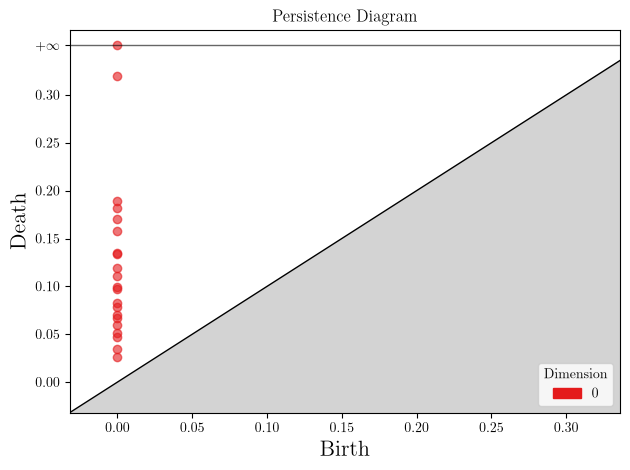

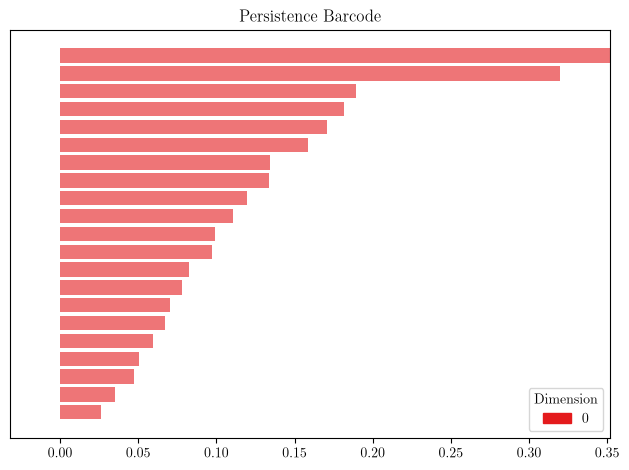

Persistence diagram saved to: /Users/alejandroucan/Documents/GitHub/BioInfo/subset/Diagramas_Persistencia/persistence_diagram.png
Persistence barcode saved to: /Users/alejandroucan/Documents/GitHub/BioInfo/subset/Diagramas_Persistencia/persistence_barcode.png

([(0, (0.0, inf)),
  (0, (0.0, 0.3199746091762024)),
  (0, (0.0, 0.18903970496506636)),
  (0, (0.0, 0.18141535099475176)),
  (0, (0.0, 0.17081495136580135)),
  (0, (0.0, 0.15836202675199615)),
  (0, (0.0, 0.13440802457881962)),
  (0, (0.0, 0.13394568062238107)),
  (0, (0.0, 0.11946641843530585)),
  (0, (0.0, 0.1107535642928338)),
  (0, (0.0, 0.09899808719512877)),
  (0, (0.0, 0.0973454550743941)),
  (0, (0.0, 0.08234620446813758)),
  (0, (0.0, 0.07813607449131789)),
  (0, (0.0, 0.07043927352398184)),
  (0, (0.0, 0.06737037401171636)),
  (0, (0.0, 0.059619092452845836)),
  (0, (0.0, 0.05083753965614471)),
  (0, (0.0, 0.04719877887833539)),
  (0, (0.0, 0.03507989612610783)),
  (0, (0.0, 0.02600895128430009))],
 <gudhi.simplex_tree.SimplexTree at 0x131107ad0>)

In [ ]:
create_complex(braycurtis_tomato)

Podemos observar que no existen ciclos persistentes, lo que indica que
estas muestras de Tomate presentan una estructura muy cercana a un
árbol, lo que sugiere que los microorganismos presentes en estas
muestras están altamente organizados y presentan una estructura
jerárquica. Esto podría indicar que los microorganismos presentes en
estas muestras tienen una relación simbiótica o mutualista, lo que
podría ser beneficioso para la planta de Tomate.

# Redes exploratorias de asociaciones entre géneros

Ahora cambia la unidad de análisis: cada nodo es un género y cada arista
representa una correlación de abundancias relativas entre muestras de
tomate de un mismo país. Esto no es una red de coocurrencia ecológica
validada: Spearman detecta asociación monotónica, y las proporciones
composicionales pueden producir correlaciones espurias.

Para hacer comparables los nodos de las redes, seleccionamos un conjunto
global fijo de hasta 10 géneros entre las muestras de tomate, en vez de
elegir 10 diferentes en cada país. No renormalizamos estos 10 géneros
para que sumen 1: conservamos las abundancias relativas respecto al
total de cada muestra. Se requiere variabilidad de cada género dentro de
cada país. Los países con menos de 5 muestras se excluyen de este
análisis exploratorio; 5 es solo un mínimo operativo, no garantía de
potencia estadística.

In [48]:
min_samples_corr = 5
selected_genera = tomato_genus_rel.mean(axis=1).nlargest(10).index.tolist()
print("Géneros fijos:", selected_genera)
eligible_countries = country_sizes[country_sizes >= min_samples_corr].index.tolist()
print("Países con suficientes muestras para exploración:", eligible_countries)
if not eligible_countries:
    print("No hay países con n ≥ 5: no se calcularán redes de Spearman.")

Géneros fijos: ['Streptomyces', 'Sphingomonas', 'Bradyrhizobium', 'Nocardioides', 'Lysobacter', 'Pseudomonas', 'Sphingobium', 'Brevundimonas', 'Micromonospora', 'Mesorhizobium']
Países con suficientes muestras para exploración: ['China', 'Mexico', 'Netherlands', 'South Africa']

# 6. Correlaciones y transformación a disimilitudes

Para cada país calculamos Spearman entre pares de géneros a través de
sus muestras. Si un género no varía, la correlación es indefinida; **no
la reemplazamos por cero**. Para mantener un conjunto común de nodos
entre países, retiramos los géneros constantes en cualquiera de los
países elegibles. Si quedan menos de dos géneros, detenemos esta
sección.

Exploramos tres transformaciones de la correlación $\rho$:

- **Absoluta:** $d=1-|\rho|$, asociación fuerte de cualquier signo.
- **Positiva:** $d=1-\max(\rho,0)$, asociación positiva fuerte.
- **Negativa:** $d=1-\max(-\rho,0)$, asociación negativa fuerte.

Estas matrices son **disimilitudes construidas para explorar
filtraciones**, no distancias métricas en general. El valor 1 para
asociaciones de signo contrario o nulas significa que la arista entra al
final de la filtración, no que exista una relación biológica.

Antes de Calcular los grafos de co-ocurrencia, ocupamos definir algunas
funciones auxiliares que nos permitirán realizar los cálculos de manera
más eficiente y organizada. Estas funciones incluirán la creación de
matrices de correlación de Spearmen, matriz de valores P, y traducción
de correlación a distancia para poder construir los grafos.

In [ ]:
def spearman_corr_matrix(working_directory: str, suffix: str, genus_df_filtered: pd.DataFrame):
    os.makedirs(working_directory, exist_ok=True)

    rel_abund = genus_df_filtered.div(genus_df_filtered.sum(axis=0), axis=1)
    rel_abund = rel_abund.replace([np.inf, -np.inf], np.nan)
    rel_abund = rel_abund.loc[rel_abund.nunique(axis=1, dropna=True) > 1]

    if rel_abund.shape[0] < 2:
        raise ValueError('At least two variable genera are needed to calculate correlations.')

    result = stats.spearmanr(rel_abund.T, axis=0, nan_policy='omit')
    genera = rel_abund.index
    corr_values = np.array(result.statistic, copy=True)
    pval_values = np.array(result.pvalue, copy=True)
    np.fill_diagonal(corr_values, 1.0)
    np.fill_diagonal(pval_values, 0.0)
    corr_matrix = pd.DataFrame(corr_values, index=genera, columns=genera)
    pval_matrix = pd.DataFrame(pval_values, index=genera, columns=genera)

    corr_matrix.to_csv(os.path.join(working_directory, f'corr_matrix_{suffix}.csv'))
    pval_matrix.to_csv(os.path.join(working_directory, f'pval_matrix_{suffix}.csv'))

    return corr_matrix, pval_matrix

In [ ]:
def corr_to_distance(working_directory: str, suffix: str, corr_matrix: pd.DataFrame):
    os.makedirs(working_directory, exist_ok=True)
    corr_values = corr_matrix.to_numpy(dtype=float, copy=True)
    indices = corr_matrix.index
    columns = corr_matrix.columns

    abs_values = 1 - np.abs(corr_values)
    positive_values = np.clip(corr_values, 0, None)
    positive_distance_values = 1 - np.abs(positive_values)
    negative_values = np.clip(corr_values, None, 0)
    negative_distance_values = 1 - np.abs(negative_values)

    for values in (abs_values, positive_distance_values, negative_distance_values):
        np.fill_diagonal(values, 0.0)

    corr_matrix_abs = pd.DataFrame(abs_values, index=indices, columns=columns)
    corr_matrix_mas = pd.DataFrame(positive_distance_values, index=indices, columns=columns)
    corr_matrix_menos = pd.DataFrame(negative_distance_values, index=indices, columns=columns)

    corr_matrix_abs.to_csv(os.path.join(working_directory, f'corr_matrix_abs_{suffix}.csv'))
    corr_matrix_mas.to_csv(os.path.join(working_directory, f'corr_matrix_mas_{suffix}.csv'))
    corr_matrix_menos.to_csv(os.path.join(working_directory, f'corr_matrix_menos_{suffix}.csv'))

    print(f'Distance matrices saved to: {working_directory}/')
    return corr_matrix_abs, corr_matrix_mas, corr_matrix_menos

#### Sudafrica

In [49]:
country_name = 'South Africa'
top_n_genera = 10
south_africa_samples = tomato_meta.loc[
    tomato_meta['country'].eq(country_name)
].index.intersection(counts_df.columns, sort=False)

if len(south_africa_samples) < 3:
    raise ValueError(f'At least three Tomato samples are needed for {country_name}.')

south_africa_counts = counts_df.loc[:, south_africa_samples]
south_africa_genus_counts_all = south_africa_counts.groupby(
    taxonomy_df['genus'].reindex(south_africa_counts.index)
).sum()
top_genera_south_africa = south_africa_genus_counts_all.sum(axis=1).nlargest(top_n_genera).index
south_africa_genus_counts = south_africa_genus_counts_all.loc[top_genera_south_africa]

corr_output_dir = os.path.join(workdir, 'Corr_Spearman', 'South_Africa')
suffix = 'tomato_south_africa'

corr_matrix_south_africa, pval_matrix_south_africa = spearman_corr_matrix(
    corr_output_dir,
    suffix,
    south_africa_genus_counts
)

(
    corr_matrix_abs_south_africa,
    corr_matrix_pos_south_africa,
    corr_matrix_neg_south_africa
) = corr_to_distance(
    corr_output_dir,
    suffix,
    corr_matrix_south_africa
)

print(f'Country: {country_name}')
print(f'Tomato samples: {len(south_africa_samples)}')
print(f'Genera included: {list(south_africa_genus_counts.index)}')
print(f'Spearman matrix shape: {corr_matrix_south_africa.shape}')
print(f'Distance matrices shape: {corr_matrix_abs_south_africa.shape}')
print(f'Outputs saved to: {corr_output_dir}')

Distance matrices saved to: /Users/alejandroucan/Documents/GitHub/BioInfo/subset/Corr_Spearman/South_Africa/
Country: South Africa
Tomato samples: 5
Genera included: ['g__Streptomyces', 'g__Bradyrhizobium', 'g__Sphingomonas', 'g__Micromonospora', 'g__Nocardioides', 'g__Pseudomonas', 'g__Mycolicibacterium', 'g__Amycolatopsis', 'g__Microbacterium', 'g__Actinoplanes']
Spearman matrix shape: (10, 10)
Distance matrices shape: (10, 10)
Outputs saved to: /Users/alejandroucan/Documents/GitHub/BioInfo/subset/Corr_Spearman/South_Africa

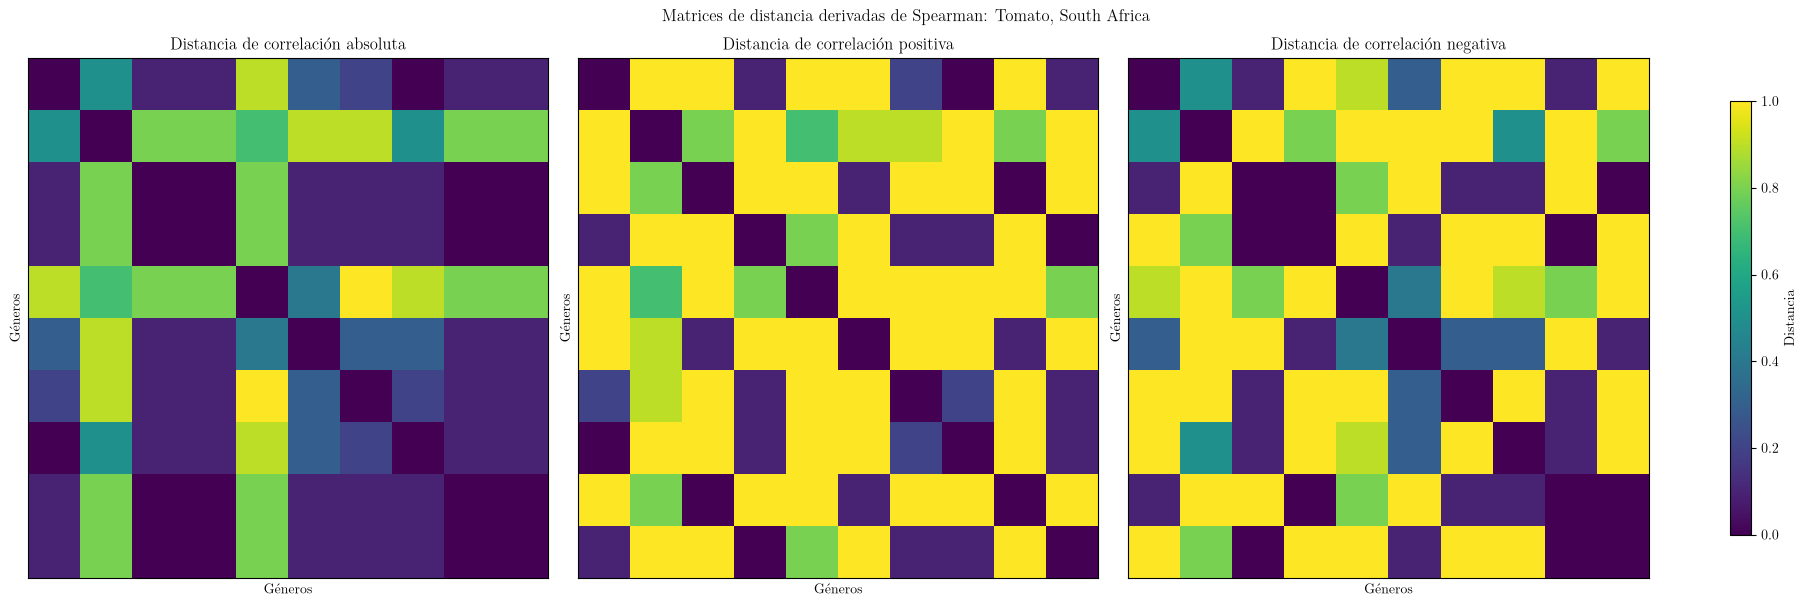

Matrix dimensions: (10, 10)
Saved to: /Users/alejandroucan/Documents/GitHub/BioInfo/subset/Corr_Spearman/South_Africa/Heatmap/tomato_south_africa_correlation_distances.jpg

In [ ]:
distance_matrices = [
    ('Absoluta', corr_matrix_abs_south_africa),
    ('Positiva', corr_matrix_pos_south_africa),
    ('Negativa', corr_matrix_neg_south_africa),
]

fig, axes = plt.subplots(1, 3, figsize=(18, 6), constrained_layout=True)
for ax, (title, matrix) in zip(axes, distance_matrices):
    image = ax.imshow(matrix.to_numpy(), cmap='viridis', vmin=0, vmax=1, interpolation='nearest')
    ax.set_title(f'Distancia de correlación {title.lower()}')
    ax.set_xlabel('Géneros')
    ax.set_ylabel('Géneros')
    ax.set_xticks([])
    ax.set_yticks([])

fig.colorbar(image, ax=axes, label='Distancia', shrink=0.8)
fig.suptitle('Matrices de distancia derivadas de Spearman: Tomato, South Africa')

heatmap_dir = os.path.join(corr_output_dir, 'Heatmap')
os.makedirs(heatmap_dir, exist_ok=True)
save_path = os.path.join(heatmap_dir, 'tomato_south_africa_correlation_distances.jpg')
fig.savefig(save_path, bbox_inches='tight', dpi=200)
plt.show()
plt.close(fig)

print(f'Matrix dimensions: {corr_matrix_abs_south_africa.shape}')
print(f'Saved to: {save_path}')

In [ ]:
# South Africa se calcula arriba. Para el ejercicio, agrega aquí los países
# que quieras analizar; por ejemplo: ['China', 'Netherlands', 'Mexico'].
countries_to_process = []
correlation_results_by_country = {}

for country_name in countries_to_process:
    country_meta = tomato_meta.loc[tomato_meta['country'].eq(country_name)]
    sample_ids = country_meta.index.intersection(counts_df.columns, sort=False)

    if len(sample_ids) < 3:
        print(f'Skipping {country_name}: only {len(sample_ids)} Tomato samples.')
        continue

    country_counts = counts_df.loc[:, sample_ids]
    genus_counts_all = country_counts.groupby(
        taxonomy_df['genus'].reindex(country_counts.index)
    ).sum()
    top_genera = genus_counts_all.sum(axis=1).nlargest(10).index
    top10_genus_counts = genus_counts_all.loc[top_genera]

    country_slug = re.sub(r'[^A-Za-z0-9_-]+', '_', country_name).strip('_')
    country_output_dir = os.path.join(workdir, 'Corr_Spearman', country_slug)
    suffix = f'tomato_{country_slug.lower()}'

    corr_matrix, pval_matrix = spearman_corr_matrix(
        country_output_dir,
        suffix,
        top10_genus_counts
    )
    distance_matrices = corr_to_distance(
        country_output_dir,
        suffix,
        corr_matrix
    )
    distance_names = ['absolute', 'positive', 'negative']
    distance_by_type = dict(zip(distance_names, distance_matrices))

    fig, axes = plt.subplots(1, 3, figsize=(18, 6), constrained_layout=True)
    for ax, (distance_type, matrix) in zip(axes, distance_by_type.items()):
        image = ax.imshow(
            matrix.to_numpy(), cmap='viridis', vmin=0, vmax=1, interpolation='nearest'
        )
        ax.set_title(f'Spearman distance: {distance_type}')
        ax.set_xlabel('Genera')
        ax.set_ylabel('Genera')
        ax.set_xticks([])
        ax.set_yticks([])
    fig.colorbar(image, ax=axes, label='Distance', shrink=0.8)
    fig.suptitle(f'Top 10 genera in Tomato samples: {country_name}')

    heatmap_dir = os.path.join(country_output_dir, 'Heatmap')
    os.makedirs(heatmap_dir, exist_ok=True)
    heatmap_path = os.path.join(heatmap_dir, f'{suffix}_correlation_distances.jpg')
    fig.savefig(heatmap_path, bbox_inches='tight', dpi=200)
    plt.show()
    plt.close(fig)

    persistence_by_type = {}
    for distance_type, matrix in distance_by_type.items():
        persistence_by_type[distance_type] = create_complex(
            matrix.to_numpy(),
            label=f'{country_slug}_{distance_type}_top_{len(corr_matrix)}'
        )

    correlation_results_by_country[country_name] = {
        'samples': list(sample_ids),
        'top_genera': list(corr_matrix.index),
        'correlation': corr_matrix,
        'pvalues': pval_matrix,
        'distance_matrices': distance_by_type,
        'persistence': persistence_by_type,
        'heatmap_path': heatmap_path,
    }

    print(
        f'{country_name}: {len(sample_ids)} samples, {len(corr_matrix)} variable top genera; '
        f'heatmap saved to {heatmap_path}'
    )

print(f'Completed analyses for {len(correlation_results_by_country)} countries.')

# 7. Redes de asociaciones por país

Se representa una arista si $d \leq 0.3$ (equivale a $|\rho|\geq 0.7$
para la versión absoluta). El umbral es ilustrativo y las aristas **no
se interpretan como interacciones**. Usamos las mismas posiciones para
los géneros en todos los países, para no sugerir diferencias por el
algoritmo de dibujo.

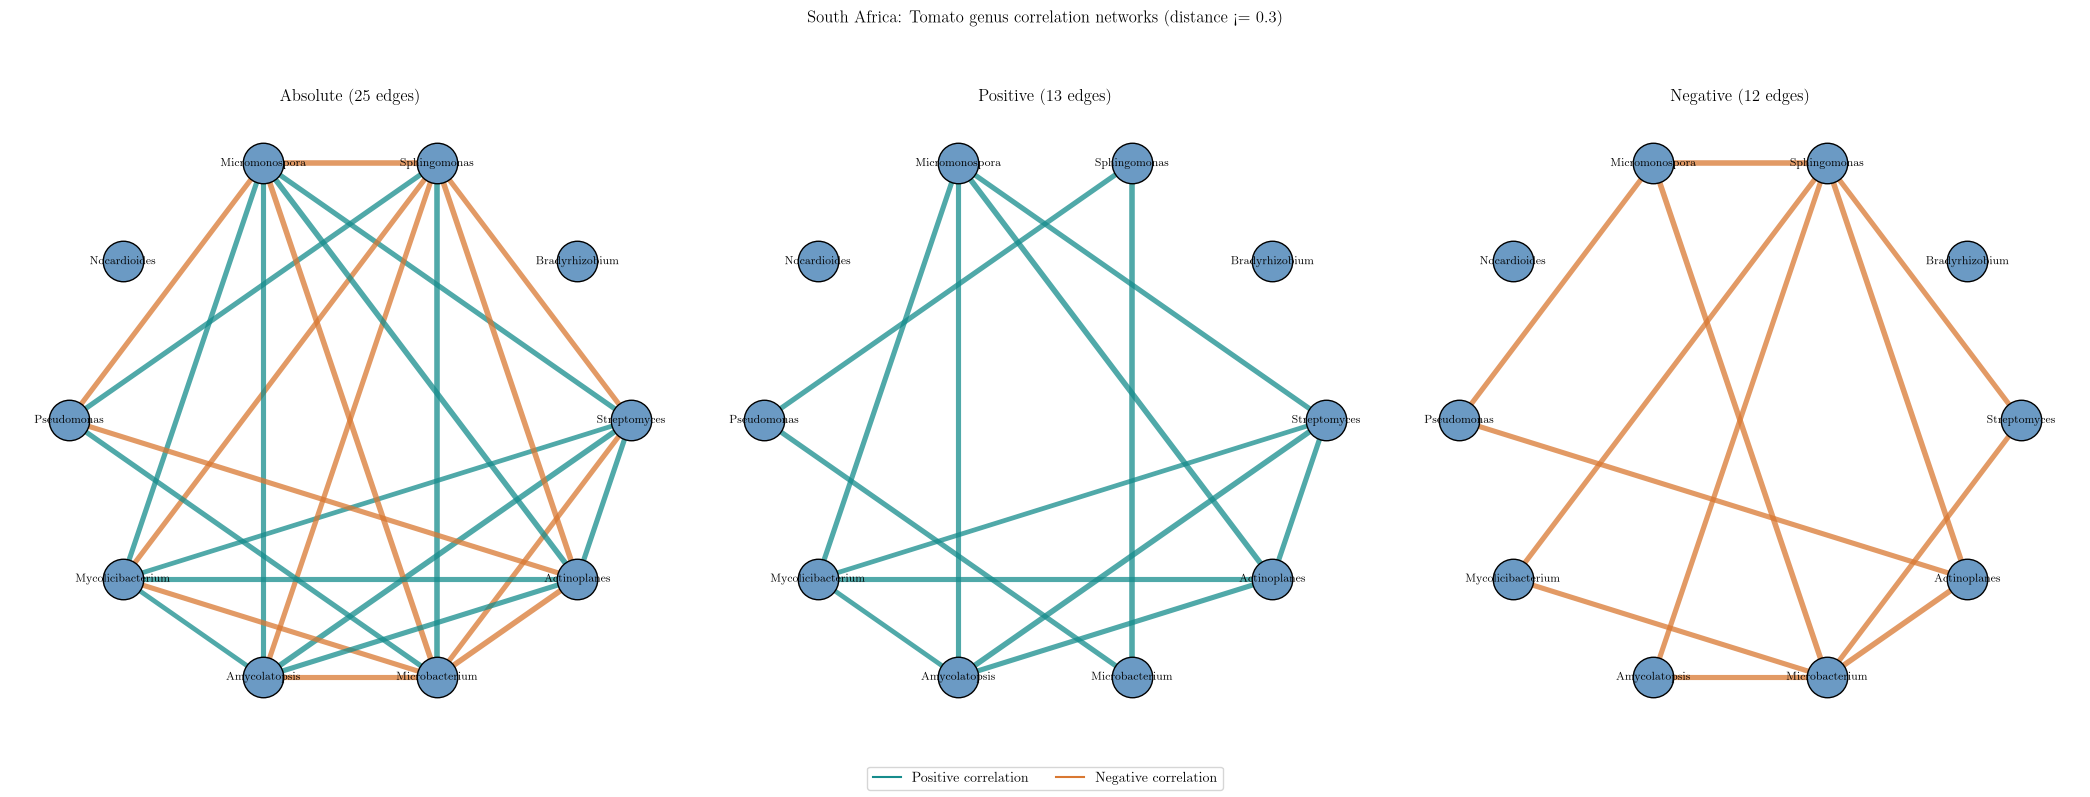

South Africa: absolute=25 edges, positive=13 edges, negative=12 edges -> /Users/alejandroucan/Documents/GitHub/BioInfo/subset/Corr_Spearman/Networks/Tomato_top10/South_Africa/South_Africa_correlation_networks.png
Generated correlation networks for 1 country.

In [ ]:
max_correlation_distance = 0.3
correlation_networks_by_country = {}
network_output_root = os.path.join(workdir, 'Corr_Spearman', 'Networks', 'Tomato_top10')

country_correlation_data = {
    country_name: {
        'correlation': result['correlation'],
        'distances': result['distance_matrices'],
    }
    for country_name, result in correlation_results_by_country.items()
}
country_correlation_data['South Africa'] = {
    'correlation': corr_matrix_south_africa,
    'distances': {
        'absolute': corr_matrix_abs_south_africa,
        'positive': corr_matrix_pos_south_africa,
        'negative': corr_matrix_neg_south_africa,
    },
}

for country_name, country_data in country_correlation_data.items():
    correlation = country_data['correlation']
    distances = country_data['distances']
    genera = correlation.index
    graph_types = ['absolute', 'positive', 'negative']
    graphs = {}
    layout_graph = nx.Graph()
    layout_graph.add_nodes_from(genera)

    for graph_type in graph_types:
        distance_matrix = distances[graph_type]
        graph = nx.Graph(country=country_name, correlation_type=graph_type)
        graph.add_nodes_from(genera)

        for genus_a, genus_b in combinations(genera, 2):
            distance = distance_matrix.loc[genus_a, genus_b]
            rho = correlation.loc[genus_a, genus_b]
            if pd.notna(distance) and pd.notna(rho) and distance <= max_correlation_distance:
                graph.add_edge(
                    genus_a,
                    genus_b,
                    distance=float(distance),
                    correlation=float(rho),
                    weight=float(abs(rho)),
                )
                if layout_graph.has_edge(genus_a, genus_b):
                    layout_graph[genus_a][genus_b]['weight'] = max(
                        layout_graph[genus_a][genus_b]['weight'], abs(float(rho))
                    )
                else:
                    layout_graph.add_edge(genus_a, genus_b, weight=abs(float(rho)))

        graphs[graph_type] = graph

    positions = nx.circular_layout(layout_graph, scale=2.2)
    fig, axes = plt.subplots(1, 3, figsize=(21, 8))

    for ax, graph_type in zip(axes, graph_types):
        graph = graphs[graph_type]
        edge_colors = [
            '#168C8C' if graph[u][v]['correlation'] >= 0 else '#D97832'
            for u, v in graph.edges
        ]
        edge_widths = [
            1 + 3 * graph[u][v]['weight']
            for u, v in graph.edges
        ]
        if graph.number_of_edges():
            nx.draw_networkx_edges(
                graph, positions, ax=ax,
                edge_color=edge_colors,
                width=edge_widths,
                alpha=0.75
            )

        nx.draw_networkx_nodes(
            graph, positions, ax=ax,
            node_size=850,
            node_color='#6B9AC4',
            edgecolors='black'
        )
        nx.draw_networkx_labels(
            graph, positions, ax=ax,
            labels={genus: str(genus).replace('g__', '') for genus in graph.nodes},
            font_size=8
        )
        ax.set_title(f'{graph_type.capitalize()} ({graph.number_of_edges()} edges)')
        ax.axis('off')

    fig.suptitle(
        f'{country_name}: Tomato genus correlation networks '
        f'(distance <= {max_correlation_distance})'
    )
    fig.legend(
        handles=[
            plt.Line2D([], [], color='#168C8C', label='Positive correlation'),
            plt.Line2D([], [], color='#D97832', label='Negative correlation'),
        ],
        loc='lower center', ncol=2
    )
    fig.tight_layout(rect=[0, 0.06, 1, 0.94])

    country_slug = re.sub(r'[^A-Za-z0-9_-]+', '_', country_name).strip('_')
    country_output_dir = os.path.join(network_output_root, country_slug)
    os.makedirs(country_output_dir, exist_ok=True)
    graph_path = os.path.join(country_output_dir, f'{country_slug}_correlation_networks.png')
    fig.savefig(graph_path, bbox_inches='tight', dpi=180)
    plt.show()
    plt.close(fig)

    correlation_networks_by_country[country_name] = graphs
    print(
        f'{country_name}: ' + ', '.join(
            f'{graph_type}={graphs[graph_type].number_of_edges()} edges'
            for graph_type in graph_types
        ) + f' -> {graph_path}'
    )

print(f'Generated correlation networks for {len(correlation_networks_by_country)} countries.')

# 8. Homología persistente de las redes de asociaciones

Construimos filtraciones de Vietoris–Rips sobre cada una de las tres
disimilitudes por país. **No** calculamos persistencia únicamente sobre
la red a umbral 0.3: la filtración utiliza todos los umbrales. Los
diagramas $H_0$ y $H_1$ describen estructuras de estas matrices de
asociación, no pruebas de interacciones ecológicas.

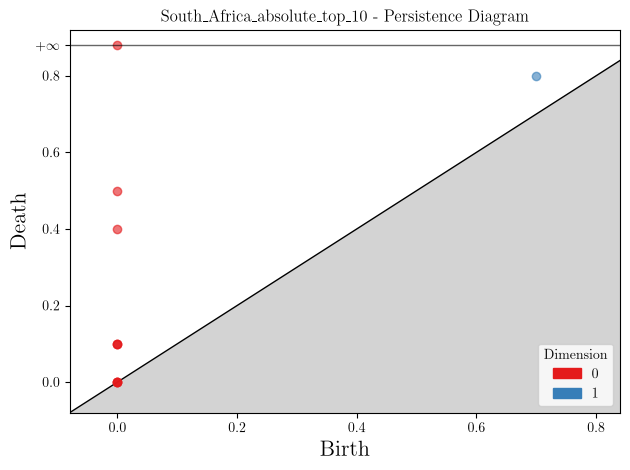

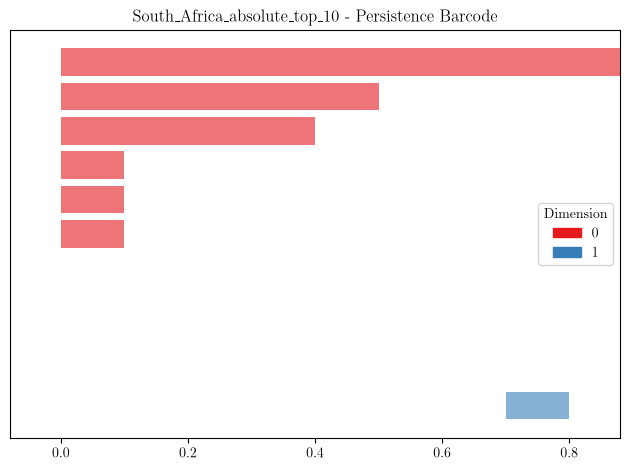

Persistence diagram saved to: /Users/alejandroucan/Documents/GitHub/BioInfo/subset/Diagramas_Persistencia/South_Africa_absolute_top_10_persistence_diagram.png
Persistence barcode saved to: /Users/alejandroucan/Documents/GitHub/BioInfo/subset/Diagramas_Persistencia/South_Africa_absolute_top_10_persistence_barcode.png

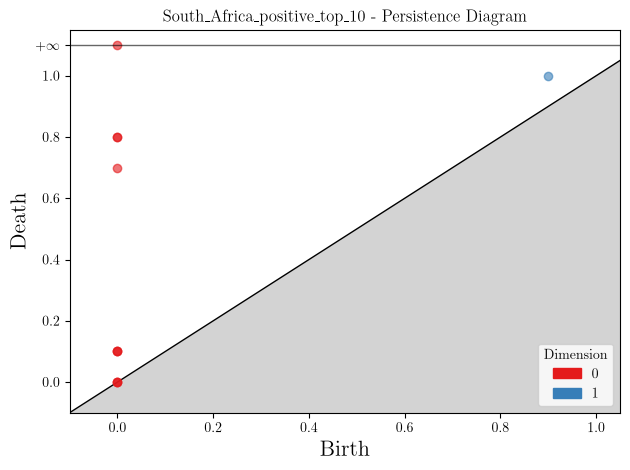

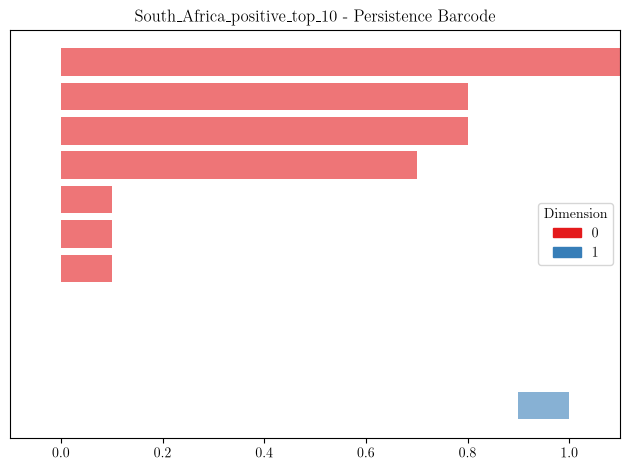

Persistence diagram saved to: /Users/alejandroucan/Documents/GitHub/BioInfo/subset/Diagramas_Persistencia/South_Africa_positive_top_10_persistence_diagram.png
Persistence barcode saved to: /Users/alejandroucan/Documents/GitHub/BioInfo/subset/Diagramas_Persistencia/South_Africa_positive_top_10_persistence_barcode.png

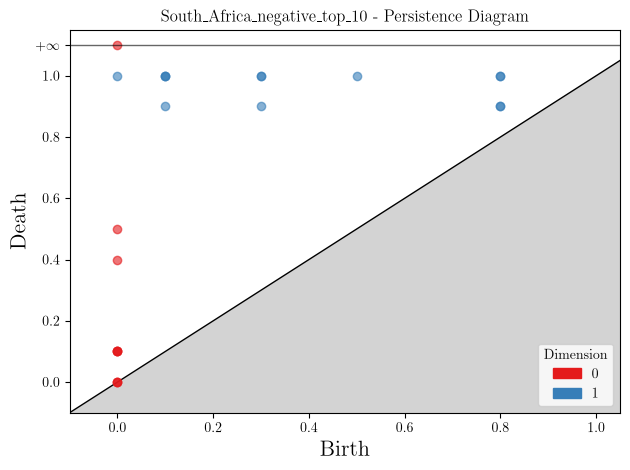

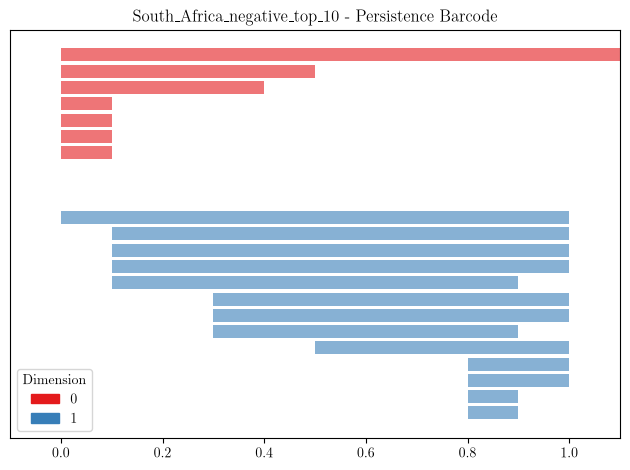

Persistence diagram saved to: /Users/alejandroucan/Documents/GitHub/BioInfo/subset/Diagramas_Persistencia/South_Africa_negative_top_10_persistence_diagram.png
Persistence barcode saved to: /Users/alejandroucan/Documents/GitHub/BioInfo/subset/Diagramas_Persistencia/South_Africa_negative_top_10_persistence_barcode.png
Generated persistence diagrams for 3 distance matrices using 10 top genera.

In [ ]:
south_africa_distance_matrices = {
    'absolute': corr_matrix_abs_south_africa,
    'positive': corr_matrix_pos_south_africa,
    'negative': corr_matrix_neg_south_africa,
}
persistence_south_africa_by_type = {}

for correlation_type, distance_matrix in south_africa_distance_matrices.items():
    distance_subset = distance_matrix.loc[
        top_genera_south_africa,
        top_genera_south_africa
    ].to_numpy()
    persistence_south_africa_by_type[correlation_type] = create_complex(
        distance_subset,
        label=f'South_Africa_{correlation_type}_top_10'
    )

print(
    f'Generated persistence diagrams for {len(persistence_south_africa_by_type)} distance matrices '
    f'using {len(top_genera_south_africa)} top genera.'
)

# 9. Comparación exploratoria de diagramas mediante Wasserstein

La distancia de Wasserstein compara diagramas de persistencia; **no mide
directamente similitud ecológica**. Usamos solo puntos con muerte finita
(en $H_0$ existe una componente esencial con muerte infinita).
Comparamos únicamente países con el mismo conjunto de géneros y la misma
transformación de correlación. Las distancias calculadas son
descriptivas y no constituyen pruebas de significación. Con pocos datos,
incluso estas comparaciones pueden ser muy inestables.

In [ ]:
from gudhi.hera import wasserstein_distance

country_persistence = {
    'South Africa': {
        distance_type: result[0]
        for distance_type, result in persistence_south_africa_by_type.items()
    }
}
for country_name, result in correlation_results_by_country.items():
    country_persistence[country_name] = {
        distance_type: persistence_result[0]
        for distance_type, persistence_result in result['persistence'].items()
    }

country_names = sorted(country_persistence)
correlation_types = ['absolute', 'positive', 'negative']
homology_dimensions = [0, 1, 2]
wasserstein_matrices = {}

for correlation_type in correlation_types:
    for dimension in homology_dimensions:
        distance_matrix = pd.DataFrame(
            0.0,
            index=country_names,
            columns=country_names
        )
        diagrams = {}
        for country_name in country_names:
            diagram = country_persistence[country_name][correlation_type]
            finite_points = [
                point for dim, point in diagram
                if dim == dimension and np.isfinite(point).all()
            ]
            diagrams[country_name] = np.asarray(finite_points, dtype=float).reshape(-1, 2)

        for i, country_a in enumerate(country_names):
            for j in range(i + 1, len(country_names)):
                country_b = country_names[j]
                diagram_a = diagrams[country_a]
                diagram_b = diagrams[country_b]
                if len(diagram_a) == 0 and len(diagram_b) == 0:
                    distance = 0.0
                else:
                    distance = wasserstein_distance(diagram_a, diagram_b, order=2)
                distance_matrix.loc[country_a, country_b] = distance
                distance_matrix.loc[country_b, country_a] = distance

        wasserstein_matrices[(correlation_type, dimension)] = distance_matrix

wasserstein_output_dir = os.path.join(
    corr_output_dir, 'Wasserstein', 'Tomato_top10'
)
os.makedirs(wasserstein_output_dir, exist_ok=True)

for correlation_type in correlation_types:
    fig, axes = plt.subplots(1, len(homology_dimensions), figsize=(16, 5), constrained_layout=True)
    max_distance = max(
        wasserstein_matrices[(correlation_type, dimension)].to_numpy().max()
        for dimension in homology_dimensions
    )
    vmax = max_distance if max_distance > 0 else 1.0

    for ax, dimension in zip(axes, homology_dimensions):
        matrix = wasserstein_matrices[(correlation_type, dimension)]
        matrix.to_csv(
            os.path.join(
                wasserstein_output_dir,
                f'wasserstein_{correlation_type}_dimension_{dimension}.csv'
            )
        )
        sns.heatmap(
            matrix,
            annot=True,
            fmt='.3f',
            cmap='viridis',
            vmin=0,
            vmax=vmax,
            square=True,
            ax=ax,
            cbar=ax is axes[-1]
        )
        ax.set_title(f'Homology dimension {dimension}')
        ax.set_xlabel('Country')
        ax.set_ylabel('Country')

    fig.suptitle(f'Wasserstein distances: {correlation_type} Spearman distances')
    figure_path = os.path.join(
        wasserstein_output_dir,
        f'wasserstein_{correlation_type}_top10.jpg'
    )
    fig.savefig(figure_path, bbox_inches='tight', dpi=180)
    plt.show()
    plt.close(fig)
    print(f'{correlation_type}: saved heatmap to {figure_path}')

print(f'Countries compared: {country_names}')
print(f'Wasserstein matrices saved to: {wasserstein_output_dir}')

# 10. Discusión y conclusiones

### ¿Qué podemos concluir?

**Parte I (muestras):** Bray–Curtis resume diferencias de composición
microbiana entre muestras de rizosfera de tomate. La red y los diagramas
muestran cómo se conectan estas muestras al variar un umbral. Si se
observan patrones por país, se describen como **hipótesis
exploratorias**, no como efectos geográficos demostrados.

**Parte II (géneros):** Spearman permite explorar asociaciones
monotónicas entre abundancias relativas de géneros dentro de cada país.
Las redes y sus diagramas caracterizan la organización de esas
**asociaciones estadísticas**, no relaciones de simbiosis, mutualismo,
antagonismo o coocurrencia demostrada. Distancias Wasserstein
pequeñas/grandes no establecen por sí solas similitud/diferencia
biológica significativa.

### Limitaciones que deben reportarse

1.  Número desigual y posiblemente pequeño de muestras por país; las
    correlaciones son sensibles a ello.
2.  Abundancias relativas son composicionales y pueden inducir
    asociaciones espurias; para inferir asociaciones microbianas serían
    preferibles enfoques especializados y validación independiente.
3.  Posibles variables de confusión (suelo, ubicación específica, lote,
    metodología de secuenciación, profundidad y procesamiento).
4.  Elección de nivel taxonómico (género) y de umbrales visuales;
    revisar sensibilidad.
5.  La filtración de Vietoris–Rips usa qué métrica.

### Preguntas para discutir en el taller

- ¿Qué cambia si se modifica el umbral de la red de Bray–Curtis?
- ¿Por qué un triángulo del grafo no necesariamente representa una clase
  de $H_1$?
- ¿Por qué no podemos interpretar una correlación positiva como
  mutualismo?
- ¿Qué cambiaría si los países tuvieran el mismo número de muestras?
- ¿Cómo distinguir una descripción topológica de una afirmación
  ecológica causal?